# 09 · Feature engineering

This is where the analysis becomes ML-ready. The stable code lives in
`barca.features` and is built with `barca features` (after `barca build`
has validated the data). This notebook documents the choices and checks
them.

| Table | Rows | Grain |
|---|---|---|
| `team_match` | per team per StatsBomb match | event aggregates (xG, PPDA, progression, ...) |
| `player_match` | per player per StatsBomb match | player event aggregates + minutes |
| `team_form` | per club per league fixture 1995-2021 | rolling results-based form |
| `event_form` | per team per fixture (Barcelona; all clubs 2015/16) | rolling event-based form |
| `elo` | per fixture | pre/post-match Elo ratings |
| `fixtures` | per league fixture | home-perspective model table |
| `barca_matches` | per Barcelona league match | Barcelona-perspective model table |

## The one rule: no information from the match being predicted

For match $t$:

$$ Features_t = f(M_1, M_2, \dots, M_{t-1}) $$

and never $f(M_t)$. Every rolling feature shifts the series by one match
*before* the window is applied:

$$ RollingxG_5(t) = \frac{1}{5}\sum_{i=t-5}^{t-1} xG_i $$

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from polars.testing import assert_frame_equal
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score

from barca import config
from barca.data import store
from barca.features import elo, event_form, tables, team_form
from barca.visualization import style

style.apply()
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(170)
pl.Config.set_tbl_hide_dataframe_shape(True)
pl.Config.set_float_precision(3)

results = store.results()
fixtures = store.features("fixtures")
barca = store.features("barca_matches")
for name in ("team_match", "player_match", "team_form", "event_form", "elo", "fixtures", "barca_matches"):
    f = store.features(name)
    print(f"{name:14s} {f.height:>7,} rows × {f.width:>3} columns")

team_match       1,738 rows × 112 columns
player_match    24,234 rows ×  73 columns
team_form       20,088 rows ×  66 columns
event_form       1,718 rows ×  86 columns
elo             10,044 rows ×  13 columns
fixtures        10,044 rows × 267 columns
barca_matches      996 rows × 267 columns


## 1. Results-based form (every club, every season)

From football-data, for each club and fixture: rolling means over the last
3, 5 and 10 league matches of points, goals for and against, goal
difference, shots, shots on target and corners (for and against); an
exponentially weighted mean of points and goal difference; form at the
same venue (last 5 home or away matches); season-to-date points and goal
difference per game; days since the previous league match; and
head-to-head over the last 4 meetings.

Windows run **across season boundaries**: form in August still reflects
May. `matches_played` tells a model how far into the season the fixture is.

In [2]:
form = store.features("team_form")
form.filter(pl.col("team") == "Barcelona", pl.col("season") == "2020/2021").select(
    "date", "opponent", "is_home", "result", "points_5", "goals_5", "goals_against_5", "sot_5", "points_ewm",
    "venue_points_5", "points_std", "matches_played", "days_rest", "h2h_points_4",
).head(8)

date,opponent,is_home,result,points_5,goals_5,goals_against_5,sot_5,points_ewm,venue_points_5,points_std,matches_played,days_rest,h2h_points_4
date,str,bool,str,f64,f64,f64,f64,f64,f64,f64,i64,i64,f64
2020-09-27,"""Villarreal""",true,"""W""",2.400,2.400,0.600,6.200,2.162,2.000,null,0,70,2.500
2020-10-01,"""Celta Vigo""",false,"""W""",2.400,2.400,0.400,5.600,2.253,2.200,3.000,1,4,1.750
2020-10-04,"""Sevilla""",true,"""D""",2.400,2.800,0.400,5.800,2.335,2.000,3.000,2,3,2.500
2020-10-17,"""Getafe""",false,"""L""",2.000,2.800,0.600,5.600,2.189,2.600,2.333,3,13,3.000
2020-10-24,"""Real Madrid""",true,"""L""",2.000,2.600,0.400,5.200,1.950,1.600,1.750,4,7,1.750
2020-10-31,"""Alavés""",false,"""D""",1.400,1.800,1.000,4.400,1.737,2.400,1.400,5,7,3.000
2020-11-07,"""Real Betis""",true,"""W""",1.000,1.200,1.200,4.400,1.657,1.400,1.333,6,7,2.250
2020-11-21,"""Atlético Madrid""",false,"""L""",1.000,1.600,1.600,5.600,1.803,2.000,1.571,7,14,2.000


The first row of the season carries last season's form, `points_std` is
empty until a match has been played, and the head-to-head column reflects
the last four meetings, however long ago.

## 2. Event-based form (Barcelona; all clubs in 2015/16)

The same idea on StatsBomb metrics: xG, xGA, non-penalty xG, big chances,
open-play and set-piece xG, possession, field tilt, PPDA, progressive
passes and carries, pressures (overall and in the final third),
counter-pressures, high recoveries, box entries, defensive-action height,
pass completion and touches in the box, over 3, 5 and 10 matches.

Windows are laid over the **complete league schedule**, not over the
matches that happen to have event data. `ev_n_w` counts how many of the
last *w* matches were covered (notebook 01: early seasons are patchy).

In [3]:
ev = store.features("event_form").filter(pl.col("team") == "Barcelona")
cov = ev.group_by("season").agg(
    pl.len().alias("matches"), pl.col("has_events").sum().alias("with_events"),
    pl.col("ev_n_5").mean().alias("mean_ev_n_5"),
).sort("season").filter(pl.col("season") >= "2004/2005")
cov

season,matches,with_events,mean_ev_n_5
str,u32,i64,f64
"""2004/2005""",38,7,0.895
"""2005/2006""",38,17,2.263
"""2006/2007""",38,26,3.026
"""2007/2008""",38,27,3.579
"""2008/2009""",38,31,4.368
"""2009/2010""",38,35,4.289
"""2010/2011""",38,33,4.579
"""2011/2012""",38,37,4.632
"""2012/2013""",38,32,4.526


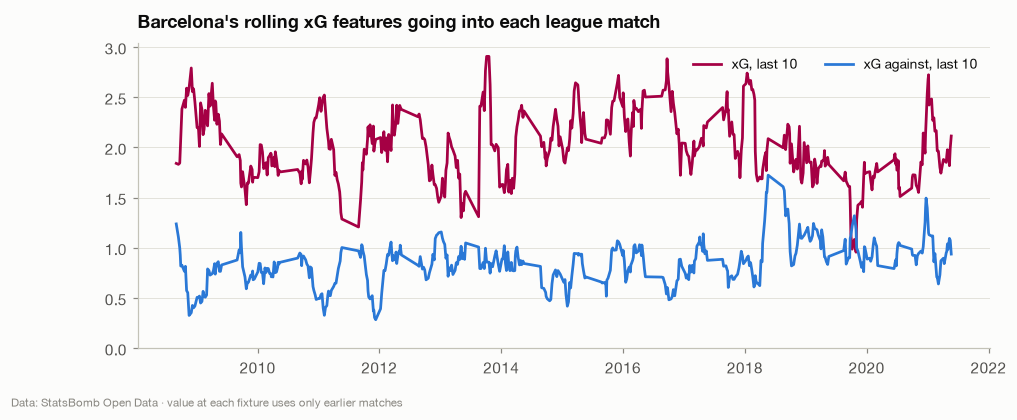

In [4]:
b = ev.filter(pl.col("season") >= "2008/2009").sort("date")
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(b["date"], b["ev_xg_10"], color=style.BARCA, lw=1.8, label="xG, last 10")
ax.plot(b["date"], b["ev_xga_10"], color=style.OPPONENT, lw=1.8, label="xG against, last 10")
ax.set_ylim(0, None)
ax.set_title("Barcelona's rolling xG features going into each league match")
ax.legend(loc="upper right", ncols=2)
style.caption(ax, style.STATSBOMB_CREDIT + " · value at each fixture uses only earlier matches")
style.savefig(fig, "09_rolling_xg")
plt.show()

## 3. Team strength: Elo

Results-based form treats a win over the bottom club like a win over the
champions. Elo does not: every result moves the rating by how surprising it
was. Details in `barca.features.elo`. Three parameters were tuned by grid
search on **1996/97-2007/08 only**, before the first season any model is
evaluated on, by minimising the Brier score of Elo's expected score:

In [5]:
best, grid = elo.tune(results)
print(best)
grid.head(8)

EloParams(k=8, home_advantage=80, regress=0.1, initial=1500.0)


k,home_advantage,regress,initial,brier
i64,i64,f64,f64,f64
8,80,0.100,1500.000,0.161
10,80,0.200,1500.000,0.161
8,80,0.200,1500.000,0.161
8,90,0.100,1500.000,0.161
6,80,0.100,1500.000,0.161
10,80,0.100,1500.000,0.161
10,90,0.200,1500.000,0.161
12,80,0.200,1500.000,0.161


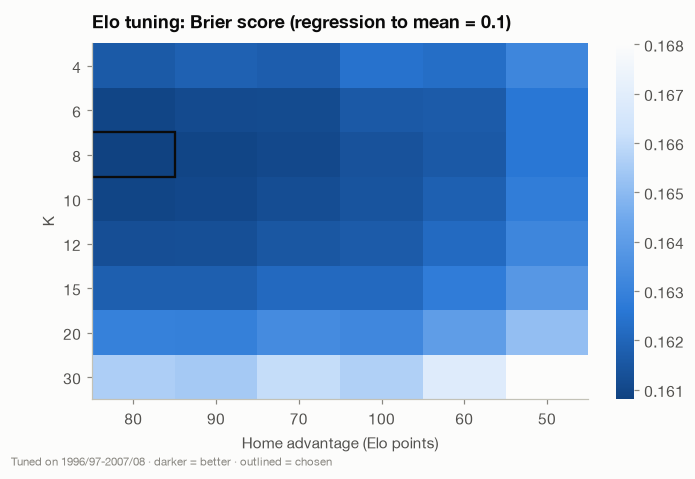

In [6]:
hm = grid.filter(pl.col("regress") == best.regress).pivot(on="home_advantage", index="k", values="brier").sort("k")
fig, ax = plt.subplots(figsize=(6.4, 4.2))
mat = hm.drop("k").to_numpy()
im = ax.imshow(mat, cmap=style.HEAT_BLUE.reversed(), aspect="auto")
ax.set_xticks(range(mat.shape[1]), hm.columns[1:])
ax.set_yticks(range(mat.shape[0]), [str(int(k)) for k in hm["k"]])
ax.set_xlabel("Home advantage (Elo points)")
ax.set_ylabel("K")
ax.set_title(f"Elo tuning: Brier score (regression to mean = {best.regress})")
ax.grid(False)
i, j = np.unravel_index(np.nanargmin(mat), mat.shape)
ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=style.INK, lw=1.5))
cb = fig.colorbar(im, ax=ax, fraction=0.04)
cb.outline.set_visible(False)
style.caption(ax, "Tuned on 1996/97-2007/08 · darker = better · outlined = chosen")
style.savefig(fig, "09_elo_tuning")
plt.show()

The optimum is interior (not on the edge of the grid): **K = 8**, **home
advantage = 80** Elo points (about 11 percentage points of expected score
between equal teams) and **10% regression to the mean** between seasons.
A small K means La Liga strength moves slowly: one result should shift
beliefs only a little.

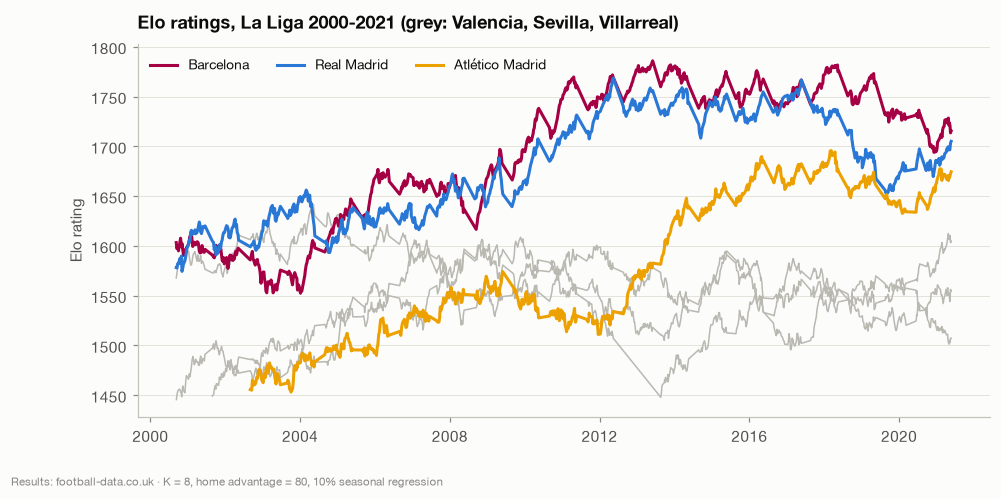

In [7]:
rated = store.features("elo")
long = elo.long_ratings(rated)
clubs = {"Barcelona": style.BARCA, "Real Madrid": style.OPPONENT, "Atlético Madrid": style.THIRD}
fig, ax = plt.subplots(figsize=(10, 4.4))
for team in ["Valencia", "Sevilla", "Villarreal"]:
    d = long.filter(pl.col("team") == team, pl.col("season_start") >= 2000)
    ax.plot(d["date"], d["elo_post"], color=style.NEUTRAL, lw=1)
for team, colour in clubs.items():
    d = long.filter(pl.col("team") == team, pl.col("season_start") >= 2000)
    ax.plot(d["date"], d["elo_post"], color=colour, lw=2, label=team)
ax.set_ylabel("Elo rating")
ax.set_title("Elo ratings, La Liga 2000-2021 (grey: Valencia, Sevilla, Villarreal)")
ax.legend(loc="upper left", ncols=3)
style.caption(ax, "Results: football-data.co.uk · K = 8, home advantage = 80, 10% seasonal regression")
style.savefig(fig, "09_elo_trajectories")
plt.show()

The trajectories tell La Liga's story: Barcelona's rise from 2004 and its
long plateau at the top, Real Madrid tracking it, Atlético's climb after
2011 under Simeone, Valencia's decline, and Barcelona's slide in 2019-21.

Is Elo's expected score calibrated on seasons it was *not* tuned on?

In [8]:
test = rated.filter(pl.col("season_start") >= 2008).with_columns(
    pl.when(pl.col("home_goals") > pl.col("away_goals")).then(1.0)
    .when(pl.col("home_goals") == pl.col("away_goals")).then(0.5).otherwise(0.0).alias("score"),
    pl.col("home_expected").cut([0.3, 0.4, 0.5, 0.6, 0.7, 0.8]).alias("bin"),
)
calib = test.group_by("bin").agg(pl.len().alias("n"), pl.col("home_expected").mean().alias("expected"),
                                 pl.col("score").mean().alias("actual")).sort("expected")
calib

bin,n,expected,actual
enum,u32,f64,f64
"""(-inf, 0.3]""",320,0.237,0.206
"""(0.3, 0.4]""",266,0.352,0.327
"""(0.4, 0.5]""",547,0.459,0.466
"""(0.5, 0.6]""",1137,0.556,0.549
"""(0.6, 0.7]""",1399,0.647,0.642
"""(0.7, 0.8]""",746,0.743,0.733
"""(0.8, inf]""",525,0.866,0.894


Expected and actual home scores line up closely across the range on
2008-2021 fixtures, which Elo never saw during tuning. Elo is a sound
strength feature and, on its own, a baseline model (milestone 12).

## 4. Relative features

Following the finding in notebook 06 (D-014), every difference compares
like with like: both sides as "higher = stronger".

In [9]:
pl.DataFrame({
    "feature": tables.RELATIVE_FEATURES,
    "definition": [
        "Elo(team) − Elo(opponent), pre-match",
        "points per game, last 5: team − opponent",
        "points per game, last 10: team − opponent",
        "goal difference per game, last 10: team − opponent",
        "(SoT for − SoT against), last 10: team − opponent",
        "team goals scored + opponent goals conceded, last 10",
        "team goals conceded + opponent goals scored, last 10",
        "season-to-date points per game: team − opponent",
        "days since last league match: team − opponent",
    ],
})

feature,definition
str,str
"""elo_diff""","""Elo(team) − Elo(opponent), pre…"
"""form_diff_5""","""points per game, last 5: team …"
"""form_diff_10""","""points per game, last 10: team…"
"""strength_diff_10""","""goal difference per game, last…"
"""sot_strength_diff_10""","""(SoT for − SoT against), last …"
"""attack_matchup_10""","""team goals scored + opponent g…"
"""defence_matchup_10""","""team goals conceded + opponent…"
"""ppg_std_diff""","""season-to-date points per game…"
"""rest_diff""","""days since last league match: …"


## 5. Proving there is no leakage

The test suite contains a check that would catch almost any form of
leakage, and it runs here live on the real data: scramble every result
from a cutoff date onwards, rebuild the whole fixture table, and require
every feature of every fixture on or before the cutoff to be identical.
Fixtures *on* the cutoff date are the sharp edge. Their own result is
scrambled, so any feature that looked at the match itself would change.

In [10]:
def rebuild(res: pl.DataFrame) -> pl.DataFrame:
    empty = pl.DataFrame(schema={"fixture_id": pl.UInt32, "is_home": pl.Boolean, "match_id": pl.Int64})
    return tables.fixture_table(res, team_form.team_form(res), elo.run(res), empty)


cutoff = date(2015, 11, 21)  # a Clásico
rng = np.random.default_rng(0)
scrambled = results.with_columns(
    pl.when(pl.col("date") >= cutoff).then(pl.Series(rng.integers(0, 7, results.height)).cast(pl.Int16))
    .otherwise(pl.col("home_goals")).alias("home_goals"),
    pl.when(pl.col("date") >= cutoff).then(pl.Series(rng.integers(0, 7, results.height)).cast(pl.Int16))
    .otherwise(pl.col("away_goals")).alias("away_goals"),
)
base, other = rebuild(results), rebuild(scrambled)
feats = tables.league_feature_list()
past = pl.col("date") <= cutoff
assert_frame_equal(base.filter(past).select("fixture_id", *feats), other.filter(past).select("fixture_id", *feats))
changed_after = (base.filter(pl.col("date") > cutoff).select(feats).to_numpy()
                 != other.filter(pl.col("date") > cutoff).select(feats).to_numpy()).any(axis=0).sum()
print(f"features checked: {len(feats)} · fixtures up to cutoff identical: yes · "
      f"features that change after the cutoff: {changed_after} of {len(feats)}")
base.filter(pl.col("date") == cutoff).select("home", "away", "home_goals", "away_goals", "h_points_5", "elo_diff")

features checked: 90 · fixtures up to cutoff identical: yes · features that change after the cutoff: 88 of 90


home,away,home_goals,away_goals,h_points_5,elo_diff
str,str,i16,i16,f64,f64
"""Deportivo La Coruña""","""Celta Vigo""",2,0,0.800,-62.965
"""Espanyol""","""Málaga""",2,0,0.800,-3.414
"""Real Madrid""","""Barcelona""",0,4,2.000,-13.485
"""Real Sociedad""","""Sevilla""",2,0,0.600,-80.337
"""Valencia""","""Las Palmas""",1,1,1.800,180.045


Nothing on or before 21 November 2015 moves, while 88 of the 90 features
change for later fixtures, as they should. The two that do not are the
rest-day features, which depend only on the schedule, not on results. The same test runs in CI
(`tests/data_quality/test_feature_leakage.py`), together with unit tests of
the rolling helpers and the Elo walk on synthetic leagues
(`tests/unit/test_leakage.py`). A feature-list test also guarantees that no
target (`result`, goals) or market column (`mkt_*`) can ever be listed as a
feature.

## 6. Coverage by season

In [11]:
key = ["h_points_5", "h_sot_10", "h_corners_10", "h_elo", "h_h2h_points_4", "h_days_rest"]
cov_f = (
    fixtures.filter(pl.col("season_start") >= 1996)
    .group_by("season").agg([pl.col(c).is_not_null().mean().alias(c.removeprefix("h_")) for c in key])
    .sort("season")
)
cov_f

season,points_5,sot_10,corners_10,elo,h2h_points_4,days_rest
str,f64,f64,f64,f64,f64,f64
"""1996/1997""",0.998,0.000,0.000,1.000,0.870,0.998
"""1997/1998""",0.997,0.000,0.000,1.000,0.950,0.997
"""1998/1999""",0.997,0.000,0.000,1.000,0.897,0.997
"""1999/2000""",0.995,0.000,0.000,1.000,0.892,0.995
"""2000/2001""",0.995,0.000,0.000,1.000,0.895,0.995
"""2001/2002""",1.000,0.000,0.000,1.000,0.979,1.000
"""2002/2003""",0.997,0.000,0.000,1.000,0.947,0.997
"""2003/2004""",1.000,0.000,0.000,1.000,0.939,1.000
"""2004/2005""",1.000,0.000,0.000,1.000,0.900,1.000


Results-based features are complete from 1996/97 (after one season of
burn-in). Shot and corner features exist from 2005/06, as found in
notebook 01. Head-to-head needs a previous meeting, so newly promoted
clubs start without it. **Modelling therefore starts in 2005/06**, the
first season with every results-based feature, and models are evaluated
from 2008/09 (D-018).

## 7. Which features carry signal?

A first, univariate look before any model: for Barcelona matches from
2005/06, how well does each feature on its own separate wins from
non-wins (ROC AUC), and how much information does it share with W/D/L
(mutual information)?

In [12]:
bm = barca.filter(pl.col("season_start") >= 2005)
y_win = (bm["result"] == "W").to_numpy()
cands = [f for f in tables.barca_feature_list(include_events=True) if f != "is_home"] + ["is_home"]
rows = []
for f in cands:
    x = bm[f].cast(pl.Float64).to_numpy()
    ok = ~np.isnan(x)
    if ok.sum() < 200 or np.nanstd(x) == 0:
        continue
    auc = roc_auc_score(y_win[ok], x[ok])
    rows.append({"feature": f, "n": int(ok.sum()), "auc_win": max(auc, 1 - auc),
                 "direction": "+" if auc >= 0.5 else "−"})
uni = pl.DataFrame(rows)
xy = bm.select([r["feature"] for r in rows]).to_pandas().fillna(bm.select([r["feature"] for r in rows]).to_pandas().median())
mi = mutual_info_classif(xy.to_numpy(), bm["result"].to_numpy(), random_state=0)
uni = uni.with_columns(pl.Series("mutual_info", mi)).sort("auc_win", descending=True)
uni.head(20)

feature,n,auc_win,direction,mutual_info
str,i64,f64,str,f64
"""elo_expected""",608,0.702,"""+""",0.065
"""opp_venue_points_5""",608,0.632,"""−""",0.058
"""elo_diff""",608,0.628,"""+""",0.029
"""opp_venue_goal_diff_5""",608,0.627,"""−""",0.012
"""is_home""",608,0.626,"""+""",0.000
"""opp_elo""",608,0.625,"""−""",0.079
"""barca_venue_goal_diff_5""",608,0.624,"""+""",0.031
"""barca_venue_points_5""",608,0.622,"""+""",0.005
"""strength_diff_10""",608,0.599,"""+""",0.063


In [13]:
def group_of(f: str) -> str:
    if "_ev_" in f:
        return "event (StatsBomb)"
    if "elo" in f:
        return "Elo"
    if f in tables.RELATIVE_FEATURES:
        return "relative"
    if f.startswith("opp_"):
        return "opponent form"
    if f.startswith("barca_"):
        return "Barcelona form"
    return "context"


uni.with_columns(pl.col("feature").map_elements(group_of, return_dtype=pl.String).alias("group")).group_by("group").agg(
    pl.len().alias("features"), pl.col("auc_win").max().alias("best_auc"), pl.col("auc_win").median().alias("median_auc"),
).sort("best_auc", descending=True)

group,features,best_auc,median_auc
str,u32,f64,f64
"""Elo""",4,0.702,0.626
"""opponent form""",38,0.632,0.541
"""context""",1,0.626,0.626
"""Barcelona form""",40,0.624,0.533
"""relative""",8,0.599,0.590
"""event (StatsBomb)""",78,0.587,0.538


Opponent strength dominates. Elo's expected score (Elo difference plus
home advantage) is the strongest single separator (AUC 0.70), followed by
the opponent's recent form, the Elo difference, home advantage and the
relative strength features, which matches notebook 06. Venue form ranks
high partly because it encodes home or away. Barcelona's own form matters
less on its own: its level is so consistently high that the variation that
decides matches comes mostly from the opponent.

Event features are individually weaker. The best are rolling big chances
and box entries (AUC ≈ 0.58-0.59), and none beats the best results-based
features on its own. Whether they add information *on top of* Elo and form
is a question for the model stage, answered with a fair comparison in
notebook 13.

None of these AUCs is large. Football outcomes are noisy, and the model
stage has to combine many weak signals rather than find one strong one.

## 8. Redundancy

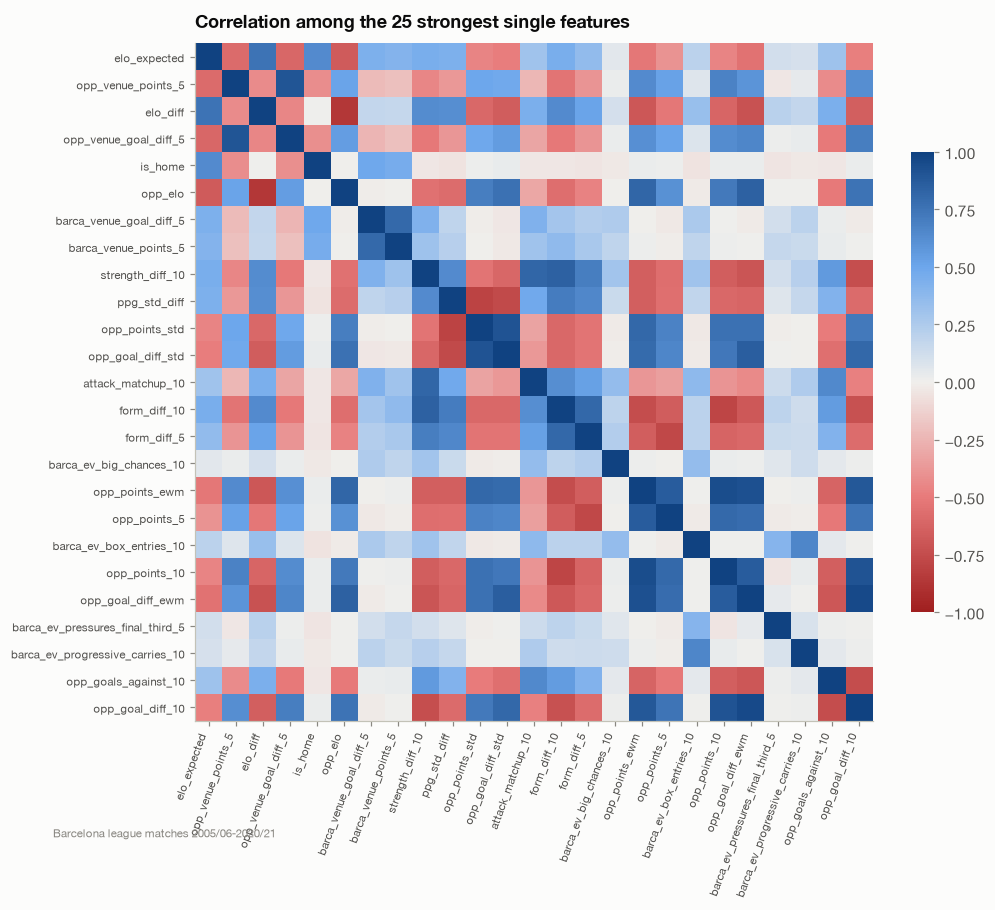

In [14]:
top = uni.head(25)["feature"].to_list()
corr = bm.select(top).cast(pl.Float64).to_pandas().corr().to_numpy()
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap=style.DIVERGING.reversed(), vmin=-1, vmax=1)
ax.set_xticks(range(len(top)), top, rotation=70, ha="right", fontsize=7.5)
ax.set_yticks(range(len(top)), top, fontsize=7.5)
ax.grid(False)
ax.set_title("Correlation among the 25 strongest single features")
cb = fig.colorbar(im, ax=ax, fraction=0.03)
cb.outline.set_visible(False)
style.caption(ax, "Barcelona league matches 2005/06-2020/21")
style.savefig(fig, "09_feature_correlation")
plt.show()

Strong blocks of correlation (opponent Elo ≈ opponent season PPG ≈
opponent goal difference) mean the signal is concentrated in a few
underlying quantities: *how strong is the opponent*, *how strong is
Barcelona right now*, and *home or away*. Tree ensembles cope with this
redundancy. For logistic regression it argues for regularisation, and for
the explanations (SHAP) it means credit may be shared across correlated
features. That caveat is documented in the XAI methodology.

## 9. The feature catalogue

Generated into `docs/feature-engineering.md`.

In [15]:
def describe(f: str) -> str:
    side = {"barca_": "Barcelona ", "opp_": "opponent ", "h_": "home ", "a_": "away "}
    prefix = next((p for p in side if f.startswith(p)), "")
    core = f[len(prefix):]
    text = core
    for w in (3, 4, 5, 10):
        if core.endswith(f"_{w}"):
            text = f"{core[: -len(str(w)) - 1].replace('_', ' ')}, mean of last {w} league matches"
    if core.startswith("ev_n_"):
        text = f"league matches with event data among the last {core.split('_')[-1]}"
    elif core.startswith("ev_"):
        text = "StatsBomb " + text.removeprefix("ev ")
    elif core.endswith("_ewm"):
        text = f"{core[:-4].replace('_', ' ')}, exponentially weighted (half-life 6 matches)"
    elif core.endswith("_std"):
        text = f"{core[:-4].replace('_', ' ')} per game, season to date"
    return (side[prefix] + text) if prefix else text


rows = [{"feature": f, "group": group_of(f), "description": describe(f)} for f in tables.barca_feature_list()]
catalog = pl.DataFrame(rows)
lines = ["| Feature | Group | Description |", "|---|---|---|"] + [
    f"| `{r['feature']}` | {r['group']} | {r['description']} |" for r in catalog.iter_rows(named=True)
]
(config.REPORTS / "feature_catalog.md").write_text("\n".join(lines) + "\n")
print(f"{catalog.height} Barcelona-model features catalogued; league model uses {len(tables.league_feature_list())}")

169 Barcelona-model features catalogued; league model uses 90


## Summary

* **One leak-free mechanism** (shift, then window) produces every rolling
  feature, and a future-scrambling test proves it on the real data.
* **Elo** is tuned on seasons before the evaluation window and is
  well calibrated on the seasons after it.
* **Relative features** use consistent signs.
* **Event features** are coverage-aware.
* **Signal is concentrated in opponent strength**, then Barcelona's form,
  then home advantage, and individually weak. The model stage has to
  combine them.

Next: team and player ratings (`10_ratings`).